In [1]:
!pip install rdflib matplotlib networkx==3.4.2

In [2]:
import pandas as pd
import json

df = pd.read_csv('../Data/Dengue_QA_multilingual_cleaned.csv')

qa_list = df.to_dict(orient='records')

with open('../Data/Dengue_QA_multilingual.json', 'w', encoding='utf-8') as f:
    json.dump(qa_list, f, ensure_ascii=False, indent=4)

print("Data saved as Dengue_QA_multilingual.json")

Data saved as Dengue_QA_multilingual.json


In [3]:
import pandas as pd
from rdflib import Graph, Literal, RDF, URIRef, Namespace

# Load cleaned CSV
df = pd.read_csv('../Data/Dengue_QA_multilingual_cleaned.csv')

# Prepare namespace
EX = Namespace("http://example.org/dengue#")
g = Graph()
g.bind("ex", EX)

# Create triples for each QA
for idx, row in df.iterrows():
    q_id = f"qa{idx+1}"
    qa_node = URIRef(f"http://example.org/dengue/{q_id}")
    g.add((qa_node, RDF.type, EX.QA_Pair))
    g.add((qa_node, EX.question_malay, Literal(row['Question (Malay)'])))
    g.add((qa_node, EX.answer_malay, Literal(row['Answer (Malay)'])))
    g.add((qa_node, EX.question_english, Literal(row['Question (English)'])))
    g.add((qa_node, EX.answer_english, Literal(row['Answer (English)'])))
    g.add((qa_node, EX.category, Literal(row['Category'])))
    if 'Source URL' in row and pd.notna(row['Source URL']):
        g.add((qa_node, EX.source, Literal(row['Source URL'])))

# Save as Turtle file
g.serialize(destination="../Data/Dengue_QA_multilingual_KG.ttl", format="turtle")
print("Knowledge graph saved as Dengue_QA_multilingual_KG.ttl")

Knowledge graph saved as Dengue_QA_multilingual_KG.ttl


### Visualise knowledge graph

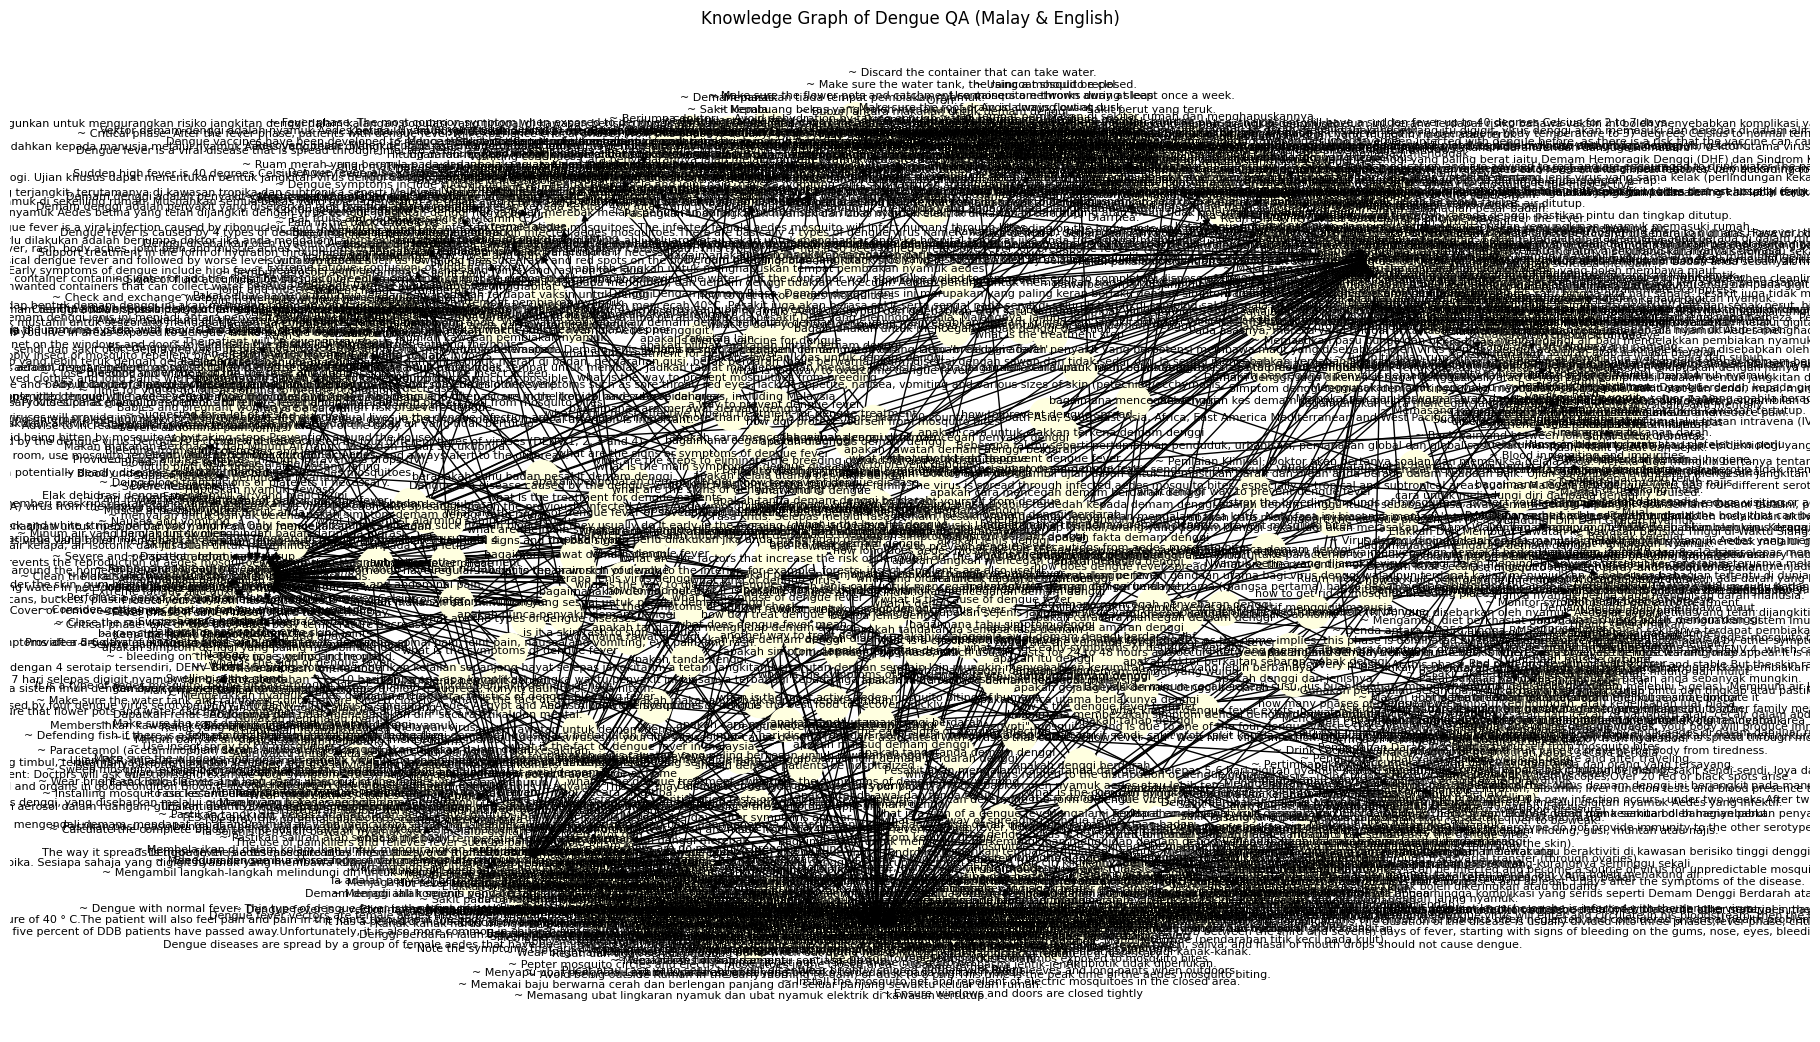

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for idx, row in df.iterrows():
    qm = row['Question (Malay)']
    am = row['Answer (Malay)']
    qe = row['Question (English)']
    ae = row['Answer (English)']
    cat = row['Category']
    # Nodes
    G.add_node(qm, label='Question (Malay)')
    G.add_node(am, label='Answer (Malay)')
    G.add_node(qe, label='Question (English)')
    G.add_node(ae, label='Answer (English)')
    G.add_node(cat, label='Category')
    # Edges
    G.add_edge(qm, am, label='hasAnswer')
    G.add_edge(qe, ae, label='hasAnswer')
    G.add_edge(qm, cat, label='hasCategory')
    G.add_edge(qe, cat, label='hasCategory')

plt.figure(figsize=(18, 10))
pos = nx.spring_layout(G, k=0.3)
nx.draw(G, pos, with_labels=True, node_color='lightyellow', node_size=600, font_size=8)
plt.title("Knowledge Graph of Dengue QA (Malay & English)")
plt.show()

### Visualise subset of knowledge graph

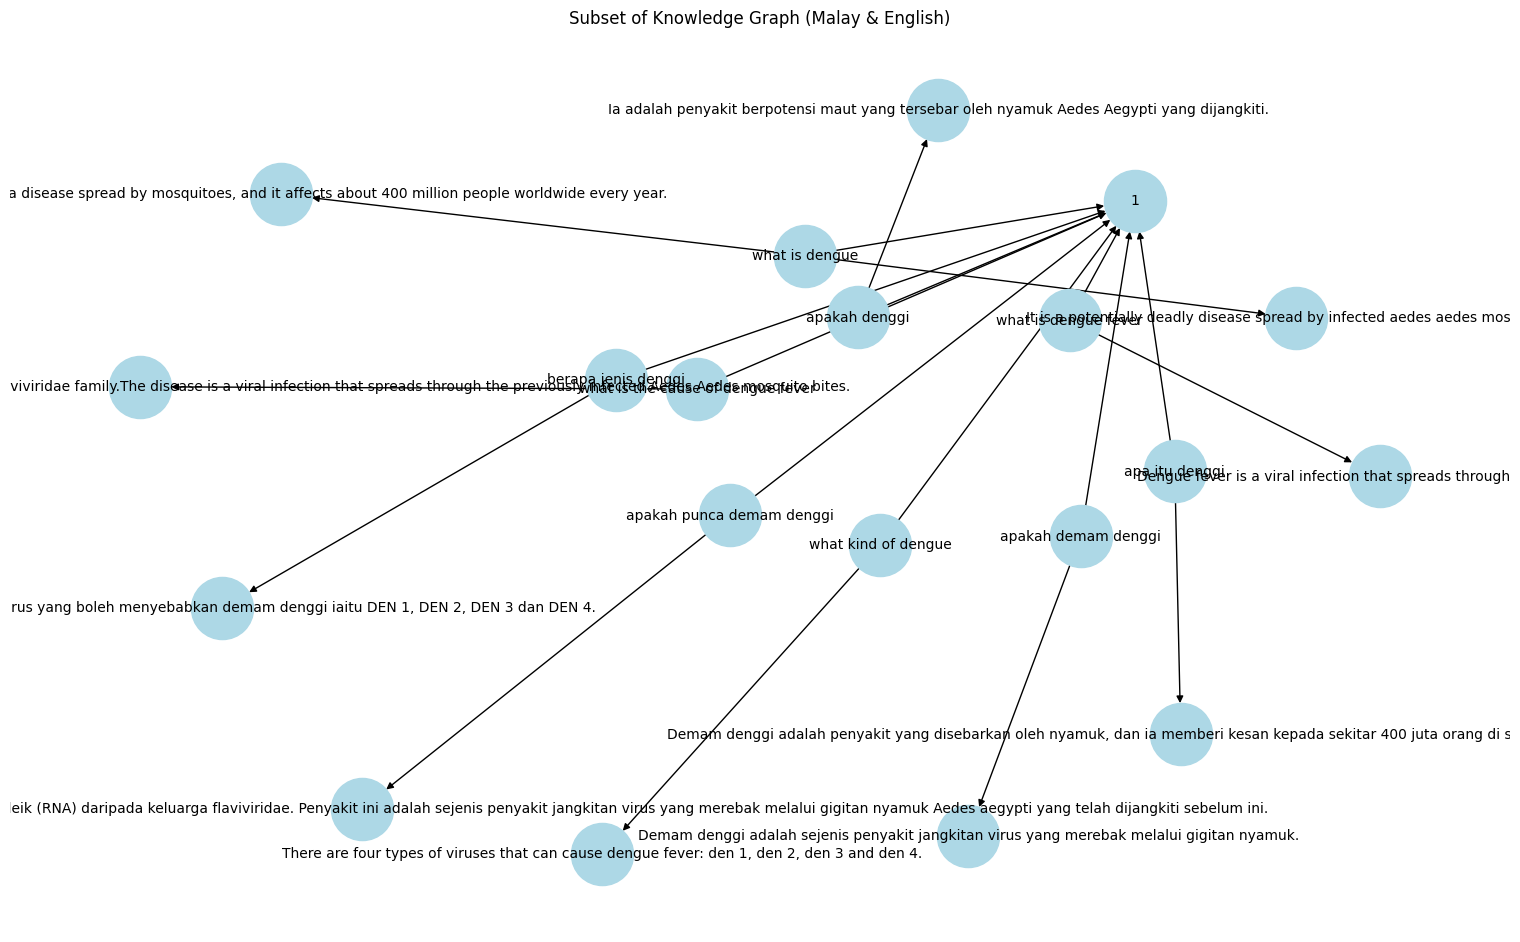

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

df_small = df.head(5)

G = nx.DiGraph()
for idx, row in df_small.iterrows():
    qm = row['Question (Malay)']
    am = row['Answer (Malay)']
    qe = row['Question (English)']
    ae = row['Answer (English)']
    cat = row['Category']
    G.add_node(qm, label='Question (Malay)')
    G.add_node(am, label='Answer (Malay)')
    G.add_node(qe, label='Question (English)')
    G.add_node(ae, label='Answer (English)')
    G.add_node(cat, label='Category')
    G.add_edge(qm, am, label='hasAnswer')
    G.add_edge(qe, ae, label='hasAnswer')
    G.add_edge(qm, cat, label='hasCategory')
    G.add_edge(qe, cat, label='hasCategory')

plt.figure(figsize=(15, 9))
pos = nx.spring_layout(G, k=0.7)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=10)
plt.title("Subset of Knowledge Graph (Malay & English)")
plt.show()

In [8]:
# Load Knowledge Graph
from rdflib import Graph

g = Graph()
g.parse("../Data/Dengue_QA_Multilingual_KG.ttl", format="turtle")

<Graph identifier=N1faafc467ce4456ba54409a83a94ae50 (<class 'rdflib.graph.Graph'>)>

In [9]:
# Find all categories and count number of Question and Answers per category
query = """
PREFIX ex: <http://example.org/dengue#>
SELECT ?cat (COUNT(?qa) as ?numQAs)
WHERE {
    ?qa ex:category ?cat .
}
GROUP BY ?cat
ORDER BY DESC(?numQAs)
"""

results = g.query(query)
for row in results:
    print(f"Category: {row['cat']} | Number of QAs: {row['numQAs']}")

Category: 1 | Number of QAs: 47
Category: 2 | Number of QAs: 37
Category: 4 | Number of QAs: 35
Category: 3 | Number of QAs: 30
